In [1]:
# Import libraries for file extraction and data handling
import os
import zipfile
import pandas as pd

# Specify the research corpus dataset
zip_path = "research_corpus.zip"

# Inspect the files stored in the ZIP archive
with zipfile.ZipFile(zip_path, "r") as zip_file:
    file_names = zip_file.namelist()

print("Number of files in the archive:", len(file_names))

print("\nFiles in the research corpus:")
for file_name in file_names:
    print(file_name)


Number of files in the archive: 5

Files in the research corpus:
research_corpus/research_1.txt
research_corpus/research_2.txt
research_corpus/research_3.txt
research_corpus/research_4.txt
research_corpus/research_5.txt


In [2]:
# Extract all research articles
with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall("extracted_research")

# Define the folder containing the articles
research_folder = os.path.join(
    "extracted_research",
    "research_corpus"
)

# Create a list to store article information
research_articles = []

# Read each research article
for file_name in sorted(os.listdir(research_folder)):

    if file_name.endswith(".txt"):

        file_path = os.path.join(research_folder, file_name)

        with open(file_path, "r", encoding="utf-8") as file:
            article_content = file.read()

        research_articles.append({
            "Article": file_name,
            "Content": article_content
        })

# Convert the research articles into a DataFrame
research_df = pd.DataFrame(research_articles)

# Display the number of articles and DataFrame dimensions
print("Total research articles:", len(research_df))
print("DataFrame shape:", research_df.shape)

# Display a preview of the research articles
display(research_df.head())


Total research articles: 5
DataFrame shape: (5, 2)


,Article,Content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [3]:
# Calculate the word count for each research article
research_df["Word Count"] = research_df["Content"].apply(
    lambda text: len(text.split())
)

# Display the articles and their word counts
display(research_df[["Article", "Word Count"]])

# Preview the first 500 characters of the first article
print("\nFirst article content preview:")
print(research_df.loc[0, "Content"][:500])


,Article,Word Count
0,research_1.txt,5602
1,research_2.txt,2416
2,research_3.txt,3828
3,research_4.txt,5922
4,research_5.txt,4027



First article content preview:
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative


# 3.2

In [4]:
# Import libraries for text preprocessing
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Prepare stopwords and lemmatiser
stop_words = set(stopwords.words("english"))

# Preserve important negation words
stop_words = stop_words.difference(
    {"no", "not", "nor", "without"}
)

lemmatizer = WordNetLemmatizer()


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\violl\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\violl\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\violl\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\violl\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\violl\AppData\Roaming\nltk_data...


In [5]:
# Define a function to clean research article text
def preprocess_article(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove unwanted characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenise the text into individual words
    tokens = word_tokenize(text)

    # Remove stopwords and very short tokens
    filtered_tokens = []

    for token in tokens:
        if token not in stop_words and len(token) > 2:
            filtered_tokens.append(token)

    # Lemmatise the remaining words
    lemmatised_tokens = []

    for token in filtered_tokens:
        lemmatised_word = lemmatizer.lemmatize(token)
        lemmatised_tokens.append(lemmatised_word)

    # Reconstruct the cleaned article
    cleaned_text = " ".join(lemmatised_tokens)

    return cleaned_text


In [6]:
# Apply text preprocessing to the research corpus
research_df["Cleaned Content"] = research_df["Content"].apply(
    preprocess_article
)

# Calculate cleaned word counts
research_df["Cleaned Word Count"] = research_df["Cleaned Content"].apply(
    lambda text: len(text.split())
)

# Calculate the percentage of words removed
research_df["Reduction (%)"] = (
    (research_df["Word Count"] - research_df["Cleaned Word Count"])
    / research_df["Word Count"]
) * 100

# Display preprocessing results
display(
    research_df[
        ["Article", "Word Count", "Cleaned Word Count", "Reduction (%)"]
    ].round(2)
)


,Article,Word Count,Cleaned Word Count,Reduction (%)
0,research_1.txt,5602,3218,42.56
1,research_2.txt,2416,1289,46.65
2,research_3.txt,3828,2167,43.39
3,research_4.txt,5922,3288,44.48
4,research_5.txt,4027,2324,42.29


In [7]:
# Display the original text sample
print("ORIGINAL ARTICLE TEXT")
print(research_df.loc[0, "Content"][:500])

# Display the cleaned text sample
print("\nCLEANED ARTICLE TEXT")
print(research_df.loc[0, "Cleaned Content"][:500])


ORIGINAL ARTICLE TEXT
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative

CLEANED ARTICLE TEXT
purpose article position mixed method research mixed research synonym natural complement traditional qualitative quantitative research present pragmatism offering attractive philosophical partner mixed method research provide framework designing conducting mixed method research briefly review paradigm war incompatibility thesis show commonality quantitative qualitative research explain tenet pragmatism explain fundamental principle mixed research appl

In [8]:
# 3.3
# Import libraries for sentence-based summarisation
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt

# Select the first research article
first_article = research_df.loc[0, "Content"]

# Split the article into sentences
sentences = sent_tokenize(first_article)

print("Total sentences in the first article:", len(sentences))


Total sentences in the first article: 168


In [12]:
# Remove repeated sentences while preserving their order
unique_sentences = list(dict.fromkeys(sentences))

# Update the sentence collection
sentences = unique_sentences

# Display the number of unique sentences
print("Unique sentences:", len(sentences))
print("Duplicate sentences removed:", 168 - len(sentences))


Unique sentences: 81
Duplicate sentences removed: 87


In [13]:
# Convert article sentences into TF-IDF features
summary_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

sentence_tfidf = summary_vectorizer.fit_transform(sentences)

# Calculate sentence importance using TF-IDF scores
sentence_scores = np.asarray(
    sentence_tfidf.sum(axis=1)
).flatten()

# Store sentences and their importance scores
sentence_df = pd.DataFrame({
    "Sentence": sentences,
    "Importance Score": sentence_scores
})

# Display the ten highest-scoring sentences
display(
    sentence_df.sort_values(
        by="Importance Score",
        ascending=False
    ).head(10)
)


,Sentence,Importance Score
74,Basic agreement has been\nreached on each of t...,8.835380
37,"Sechrest and Sidani (1995, p. 78) point out\nt...",5.839712
13,These\npurists contend that multiple-construct...,5.800733
64,"Again, however,\na strong relativism or strong...",5.754946
10,These researchers have\ntraditionally called f...,5.729768
58,"), developing instruments that are believed to...",5.695668
5,"Campbell & Stanley, 1963; Lincoln & Guba, 1985...",5.542181
41,Although certain methodologies tend to be asso...,5.279572
61,"Some qualitative purists (e.g., Guba, 1990) op...",5.218724
32,Methodological work on the mixed methods resea...,5.036478


In [14]:
# Select the five most important sentences
top_sentence_indices = np.argsort(sentence_scores)[-5:]

# Restore the original sentence order
top_sentence_indices = sorted(top_sentence_indices)

# Combine selected sentences into a summary
article_summary = " ".join(
    sentences[index] for index in top_sentence_indices
)

# Display the generated summary
print("FIRST RESEARCH ARTICLE SUMMARY")
print("--------------------------------")
print(article_summary)

# Display summary length
print("\nOriginal word count:", len(first_article.split()))
print("Summary word count:", len(article_summary.split()))


FIRST RESEARCH ARTICLE SUMMARY
--------------------------------
These researchers have
traditionally called for rhetorical neutrality, involving a formal
Mixed Methods Research:
A Research Paradigm Whose Time Has Come
by R. Burke Johnson and Anthony J. Onwuegbuzie
writing style using the impersonal passive voice and technical terminology, in which establishing and describing social laws is the
major focus (Tashakkori & Teddlie, 1998). These
purists contend that multiple-constructed realities abound, that
time- and context-free generalizations are neither desirable nor
possible, that research is value-bound, that it is impossible to differentiate fully causes and effects, that logic flows from specific
to general (e.g., explanations are generated inductively from the
data), and that knower and known cannot be separated because
the subjective knower is the only source of reality (Guba, 1990). Sechrest and Sidani (1995, p. 78) point out
that both methodologies “describe their data, constr

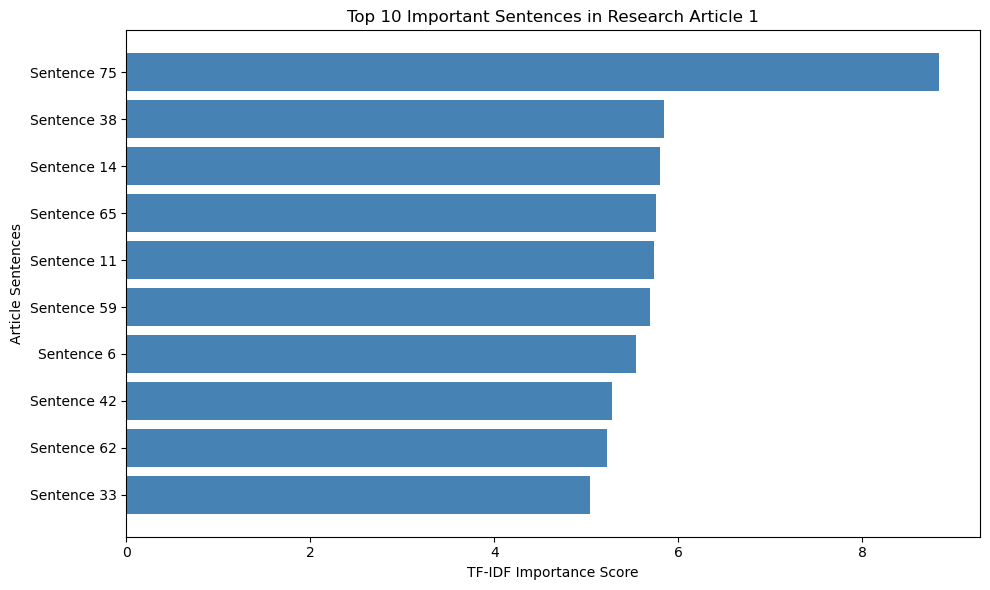

In [15]:
# Identify the ten highest-scoring sentences
top_sentences = sentence_df.nlargest(
    10,
    "Importance Score"
).copy()

# Create short sentence labels
top_sentences["Sentence Label"] = [
    f"Sentence {index + 1}"
    for index in top_sentences.index
]

# Plot sentence importance scores
plt.figure(figsize=(10, 6))

plt.barh(
    top_sentences["Sentence Label"],
    top_sentences["Importance Score"],
    color="steelblue"
)

plt.title("Top 10 Important Sentences in Research Article 1")
plt.xlabel("TF-IDF Importance Score")
plt.ylabel("Article Sentences")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [16]:
# 3.4
# Select the remaining four research articles
remaining_articles = research_df[
    research_df["Article"] != "research_1.txt"
].copy()

# Display the selected articles
print("Number of remaining articles:", len(remaining_articles))

display(
    remaining_articles[["Article", "Word Count", "Cleaned Word Count"]]
)


Number of remaining articles: 4


,Article,Word Count,Cleaned Word Count
1,research_2.txt,2416,1289
2,research_3.txt,3828,2167
3,research_4.txt,5922,3288
4,research_5.txt,4027,2324


In [17]:
# Import sentence tokenisation
from nltk.tokenize import sent_tokenize

# Combine the original content of the remaining articles
combined_text = " ".join(
    remaining_articles["Content"].fillna("").astype(str)
)

# Split the combined content into sentences
combined_sentences = sent_tokenize(combined_text)

# Remove repeated and empty sentences
combined_sentences = [
    sentence.strip()
    for sentence in dict.fromkeys(combined_sentences)
    if sentence.strip()
]

# Display corpus information
print("Total articles:", len(remaining_articles))
print("Total words:", len(combined_text.split()))
print("Total unique sentences:", len(combined_sentences))


Total articles: 4
Total words: 16193
Total unique sentences: 574


In [18]:
# Import feature extraction and dimensionality reduction
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import numpy as np

# Convert sentences into numerical TF-IDF features
lsa_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

sentence_tfidf = lsa_vectorizer.fit_transform(
    combined_sentences
)

# Define the number of latent semantic components
number_of_topics = min(
    5,
    sentence_tfidf.shape[0] - 1,
    sentence_tfidf.shape[1] - 1
)

# Apply Latent Semantic Analysis using SVD
lsa_model = TruncatedSVD(
    n_components=number_of_topics,
    random_state=42
)

# Transform sentences into latent semantic features
sentence_topics = lsa_model.fit_transform(
    sentence_tfidf
)

# Display results
print("TF-IDF matrix shape:", sentence_tfidf.shape)
print("LSA matrix shape:", sentence_topics.shape)
print(
    "Explained variance ratio:",
    round(lsa_model.explained_variance_ratio_.sum(), 4)
)


TF-IDF matrix shape: (574, 5000)
LSA matrix shape: (574, 5)
Explained variance ratio: 0.0418


In [19]:
# Calculate sentence importance using LSA component magnitudes
sentence_scores = np.linalg.norm(
    sentence_topics,
    axis=1
)

# Create a DataFrame containing sentences and scores
lsa_sentence_df = pd.DataFrame({
    "Sentence": combined_sentences,
    "Importance Score": sentence_scores
})

# Rank sentences by importance
lsa_sentence_df = lsa_sentence_df.sort_values(
    by="Importance Score",
    ascending=False
)

# Display the ten highest-scoring sentences
display(lsa_sentence_df.head(10))


,Sentence,Importance Score
194,DEVELOPMENTAL RESEARCH • 1103\nTABLE 41.2.,0.744111
116,DEVELOPMENTAL RESEARCH • 1101\nTABLE 41.1.,0.744111
66,"In its simplest form,\ndevelopmental research ...",0.632498
483,Data triangulation\nData triangulation is ofte...,0.590362
185,41.2.4.1 The Focus of Developmental Research.,0.576892
188,Table 41.2 portrays the relationships\nbetween...,0.572971
69,The purposes of this chapter are to\n explore...,0.545078
552,The Postparadigm Shift\nSince Denzin initially...,0.539545
563,"The Triangulation Confusion\nFrequently, we se...",0.520168
497,in a qualitative case\nstudy or ethnography wo...,0.502871


In [20]:
# Select the ten most important sentences
summary_sentence_count = 10

top_sentence_indices = np.argsort(
    sentence_scores
)[-summary_sentence_count:]

# Restore the original sentence order
top_sentence_indices = sorted(top_sentence_indices)

# Generate the combined research summary
aggregate_summary = " ".join(
    combined_sentences[index]
    for index in top_sentence_indices
)

# Display the summary
print("AGGREGATE RESEARCH SUMMARY")
print("--------------------------")
print(aggregate_summary)

# Compare original and summarised word counts
original_word_count = len(combined_text.split())
summary_word_count = len(aggregate_summary.split())

reduction_percentage = (
    (original_word_count - summary_word_count)
    / original_word_count
) * 100

print("\nOriginal word count:", original_word_count)
print("Summary word count:", summary_word_count)
print(f"Text reduction: {reduction_percentage:.2f}%")


AGGREGATE RESEARCH SUMMARY
--------------------------
In its simplest form,
developmental research can be either
 the study of the process and impact of specific instructional
design and development efforts; or
 a situation in which someone is performing instructional design, development, or evaluation activities and studying the
process at the same time; or
 the study of the instructional design, development, and evaluation process as a whole or of particular process components. The purposes of this chapter are to
 explore the nature and background of developmental research;
 describe the major types of developmental research by examining a range of representative projects;
 analyze the methodological approaches used in the various
types of developmental research;
 describe the issues, findings, and trends in recent developmental research; and
 discuss the future of this type of research in our field. DEVELOPMENTAL RESEARCH • 1101
TABLE 41.1. 41.2.4.1 The Focus of Developmenta

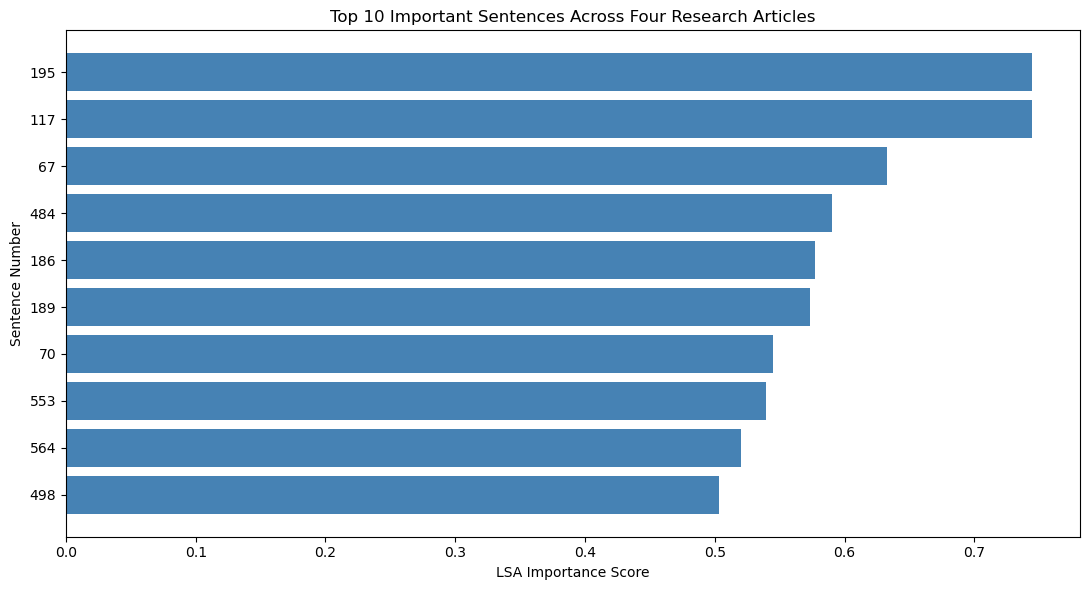

In [21]:
# Import plotting library
import matplotlib.pyplot as plt

# Select the ten highest-scoring sentences
top_10_sentences = lsa_sentence_df.head(10).copy()

# Identify sentence positions in the original corpus
top_10_sentences["Sentence Number"] = [
    combined_sentences.index(sentence) + 1
    for sentence in top_10_sentences["Sentence"]
]

# Create the horizontal bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    top_10_sentences["Sentence Number"].astype(str),
    top_10_sentences["Importance Score"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title("Top 10 Important Sentences Across Four Research Articles")
plt.xlabel("LSA Importance Score")
plt.ylabel("Sentence Number")

plt.tight_layout()
plt.show()


,Term,Importance Score
4852,triangulation,0.581399
4535,research,0.577618
182,alpha,0.428245
1838,developmental research,0.423614
1835,developmental,0.420642
1490,data,0.405596
1773,development,0.391218
1664,design,0.388020
72,41,0.332278
1435,cronbach,0.304052


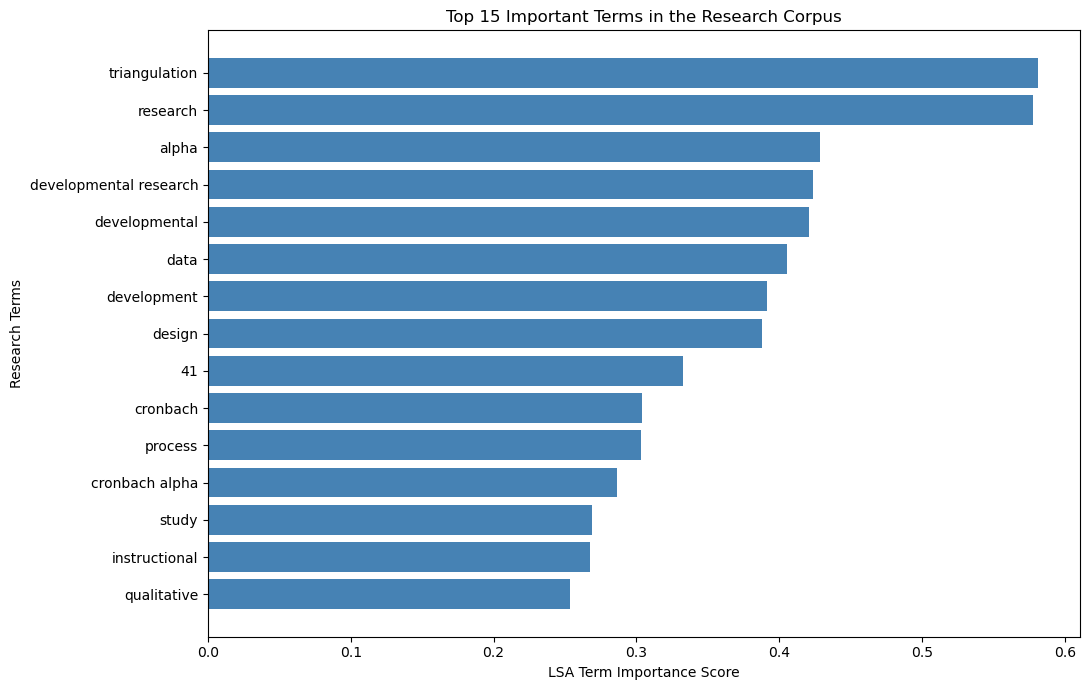

In [22]:
# Extract the terms used in the TF-IDF representation
feature_names = lsa_vectorizer.get_feature_names_out()

# Calculate each term's contribution across LSA components
term_scores = np.linalg.norm(
    lsa_model.components_,
    axis=0
)

# Create a DataFrame for term importance
term_df = pd.DataFrame({
    "Term": feature_names,
    "Importance Score": term_scores
})

# Select the 15 highest-scoring terms
top_15_terms = term_df.sort_values(
    by="Importance Score",
    ascending=False
).head(15)

# Display the results
display(top_15_terms)

# Visualise important research terms
plt.figure(figsize=(11, 7))

plt.barh(
    top_15_terms["Term"],
    top_15_terms["Importance Score"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title("Top 15 Important Terms in the Research Corpus")
plt.xlabel("LSA Term Importance Score")
plt.ylabel("Research Terms")

plt.tight_layout()
plt.show()


Latent Semantic Analysis (LSA) was applied to summarise four research articles collectively using TF-IDF feature extraction and Truncated Singular Value Decomposition (SVD).

The combined corpus contained 16,193 words and 574 unique sentences. The generated summary contained 275 words, representing a 98.30% reduction in text length.

In [23]:
research_df.to_csv("research_articles_cleaned.csv", index=False)
print("Dataset saved successfully!")

Dataset saved successfully!
